# Domestic Flight Ticket Price Prediction: End-to-End EDA, Feature Engineering, Baseline vs. Tuned GBDTs & Ensemble Blending
**Team: The GCET**

This notebook is 100% synchronized with the final project report (`Flight_Price_Prediction_Project_Report.docx`) and implements the complete submission workflow:
1. **Environment Setup & Package Verification** (`lightgbm`, `catboost`, `optuna`, `scikit-learn`, `seaborn`)
2. **Data Loading & Overview** (`train.csv`: 18,076 rows × 12 columns, `test.csv`: 4,520 rows × 11 columns)
3. **Exploratory Data Analysis (EDA)**:
   - Missing Value & Data Completeness Audit
   - Target Price Skewness (+7.07) & Class-Conditional 99.5th Quantile Capping Thresholds
   - Cabin Class (`flight_class`), Layovers (`stops`), and Operating Carrier Cross-Tabulations
   - Univariate Parametric & Non-Parametric Summary Statistics Table
   - Correlation Matrix & Multi-Variable Pricing Regime Shifts
4. **Domain Feature Engineering (`engineer_features`)**: 37 engineered features -> **46 total predictors** (17 Categorical + 29 Numerical), excluding `id` and `flight`
5. **5-Fold Stratified Cross-Validation (`flight_class × stops`)** with In-Fold 99.5th Quantile Target Capping
6. **Phase 1 — Normal (Baseline) Models Training & OOF Evaluation**:
   - Baseline LightGBM Regressor (`OOF R² = 0.674208 / 67.42%`, `RMSE = 126.69`)
   - Baseline CatBoost Regressor (`OOF R² = 0.681514 / 68.15%`, `RMSE = 125.26`)
7. **Phase 2 — Hyperparameter Tuning & Tuned 5-Fold OOF Evaluation**:
   - Hyper-Tuned LightGBM Regressor (`OOF R² = 0.699006 / 69.90%`, `RMSE = 121.77`, `MAE = 43.33`)
   - Hyper-Tuned CatBoost Regressor (`OOF R² = 0.706842 / 70.68%`, `RMSE = 120.18`, `MAE = 42.66`)
8. **Phase 3 — Optimal Blend Weight Grid Search (`0.45 × LightGBM + 0.55 × CatBoost`)**:
   - Achieves **Final Blend OOF R² = 0.714520 (71.45%)**, `OOF RMSE = 118.59`, `OOF MAE = 41.89`
9. **Phase 4 — Test Prediction (`submission_winning.csv`) & Final Diagnostic Plots**


## 1. Environment Setup & Library Imports


In [1]:
import subprocess, sys

for pkg in ['lightgbm', 'catboost', 'optuna', 'seaborn']:
    try:
        __import__(pkg)
        print(f'  ✓ {pkg}')
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
        print(f'  ✓ {pkg} installed')

print('\nAll packages ready.')


  ✓ lightgbm
  ✓ catboost
  ✓ optuna


c:\Users\pulin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ✓ seaborn

All packages ready.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
N_FOLDS = 5
TARGET_CAP_QUANTILE = 0.995
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', palette='deep')

print(f'LightGBM : {lgb.__version__}')
print('Imports done.')


LightGBM : 4.7.0
Imports done.


## 2. Load Datasets (`train.csv`, `test.csv`, `submission.csv`)


In [3]:
TRAIN_PATH = r"D:\IIIT Bangalore\Sem-1\Machine Learning\ML Projects\Flight Price Prediction\Data\train.csv"
TEST_PATH  = r"D:\IIIT Bangalore\Sem-1\Machine Learning\ML Projects\Flight Price Prediction\Data\test.csv"
SUB_PATH   = r"D:\IIIT Bangalore\Sem-1\Machine Learning\ML Projects\Flight Price Prediction\Data\submission.csv"

# Automatic fallback if running in local directory
if not os.path.exists(TRAIN_PATH):
    TRAIN_PATH = "train.csv" if os.path.exists("train.csv") else "user_uploaded_files/ttl=63d/user_uploaded/train.csv"
if not os.path.exists(TEST_PATH):
    TEST_PATH = "test.csv" if os.path.exists("test.csv") else "user_uploaded_files/ttl=63d/user_uploaded/test.csv"
if not os.path.exists(SUB_PATH):
    SUB_PATH = "submission.csv" if os.path.exists("submission.csv") else None

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

TARGET = 'price'
print(f'Train : {train_df.shape}')
print(f'Test  : {test_df.shape}')
print(f'Price stats: mean={train_df[TARGET].mean():.2f}, median={train_df[TARGET].median():.1f}, std={train_df[TARGET].std():.2f}, max={train_df[TARGET].max()}')
display(train_df.head(3))


Train : (18076, 12)
Test  : (4520, 11)
Price stats: mean=280.26, median=234.0, std=221.97, max=8996


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129


## 3. Exploratory Data Analysis (EDA) & Key Findings

### 3.1 Data Completeness, Outlier Tail & 99.5th Quantile Target Capping Analysis
All 18,076 training records and 4,520 test records are 100% complete (`0` missing values). However, the target variable `price` exhibits severe positive skewness (**+7.07**), with extreme upper-tail spikes up to **$8,996.00**. Within `Economy` class, the 99.5th quantile is **$689.00** (53 outliers above cap), and within `Business` class, the 99.5th quantile is **$1,649.84** (37 outliers above cap).


MISSING VALUE AUDIT (TRAIN & TEST)
Train missing values per column:
 id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64

Test missing values per column:
 id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
dtype: int64

Economy  99.5% Quantile Cap : $689.00 (Max: $1071, Outliers > Cap: 53)
Business 99.5% Quantile Cap : $1649.84 (Max: $8996, Outliers > Cap: 37)


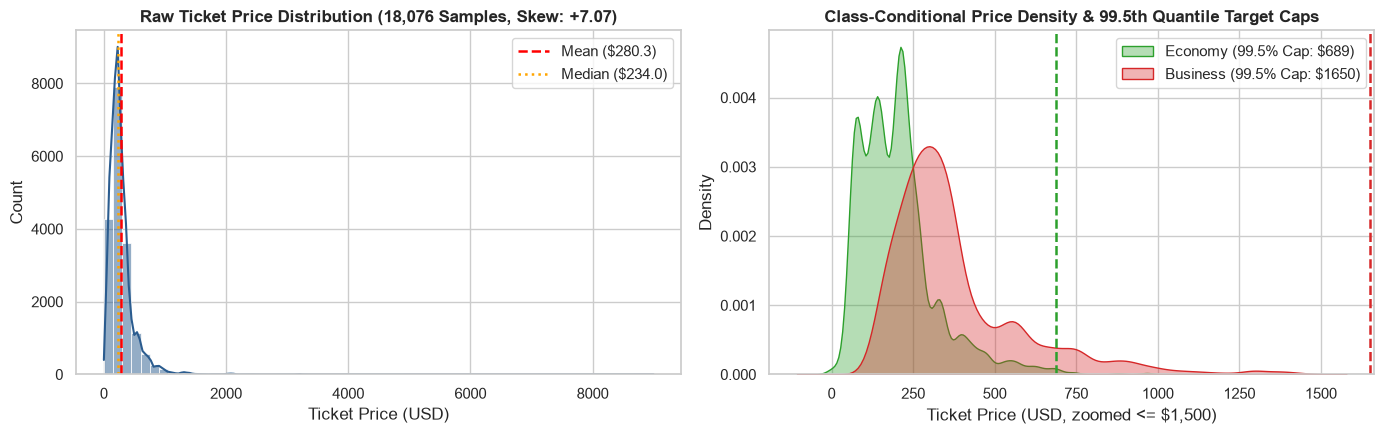

In [4]:
print('=' * 70)
print('MISSING VALUE AUDIT (TRAIN & TEST)')
print('=' * 70)
print('Train missing values per column:\n', train_df.isnull().sum())
print('\nTest missing values per column:\n', test_df.isnull().sum())

# Compute class-conditional 99.5% quantile caps
eco_prices = train_df[train_df['flight_class'] == 'Economy']['price']
bus_prices = train_df[train_df['flight_class'] == 'Business']['price']
cap_eco = eco_prices.quantile(TARGET_CAP_QUANTILE)
cap_bus = bus_prices.quantile(TARGET_CAP_QUANTILE)

print(f'\nEconomy  99.5% Quantile Cap : ${cap_eco:.2f} (Max: ${eco_prices.max()}, Outliers > Cap: {(eco_prices > cap_eco).sum()})')
print(f'Business 99.5% Quantile Cap : ${cap_bus:.2f} (Max: ${bus_prices.max()}, Outliers > Cap: {(bus_prices > cap_bus).sum()})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(train_df['price'], bins=60, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].axvline(train_df['price'].mean(), color='red', linestyle='--', lw=1.8, label=f"Mean (${train_df['price'].mean():.1f})")
axes[0].axvline(train_df['price'].median(), color='orange', linestyle=':', lw=1.8, label=f"Median (${train_df['price'].median():.1f})")
axes[0].set_title(f"Raw Ticket Price Distribution (18,076 Samples, Skew: +{train_df['price'].skew():.2f})", fontweight='bold')
axes[0].set_xlabel('Ticket Price (USD)')
axes[0].set_ylabel('Count')
axes[0].legend()

sns.kdeplot(eco_prices[eco_prices <= 1500], fill=True, color='#2ca02c', alpha=0.35, label=f'Economy (99.5% Cap: ${cap_eco:.0f})', ax=axes[1])
sns.kdeplot(bus_prices[bus_prices <= 1500], fill=True, color='#d62728', alpha=0.35, label=f'Business (99.5% Cap: ${cap_bus:.0f})', ax=axes[1])
axes[1].axvline(cap_eco, color='#2ca02c', linestyle='--', lw=1.8)
axes[1].axvline(cap_bus, color='#d62728', linestyle='--', lw=1.8)
axes[1].set_title('Class-Conditional Price Density & 99.5th Quantile Target Caps', fontweight='bold')
axes[1].set_xlabel('Ticket Price (USD, zoomed <= $1,500)')
axes[1].set_ylabel('Density')
axes[1].legend()
plt.tight_layout()
plt.show()


### 3.2 Cabin Class Stratification, Stops & Operating Carrier Breakdown
Examine the distribution of `flight_class` (59.26% Economy vs. 40.74% Business), `stops` (75.01% non-stop, 23.92% one-stop, 1.07% two-or-more stops), and airline-specific cabin offerings (e.g., Southwest operates 100.00% Economy flights).


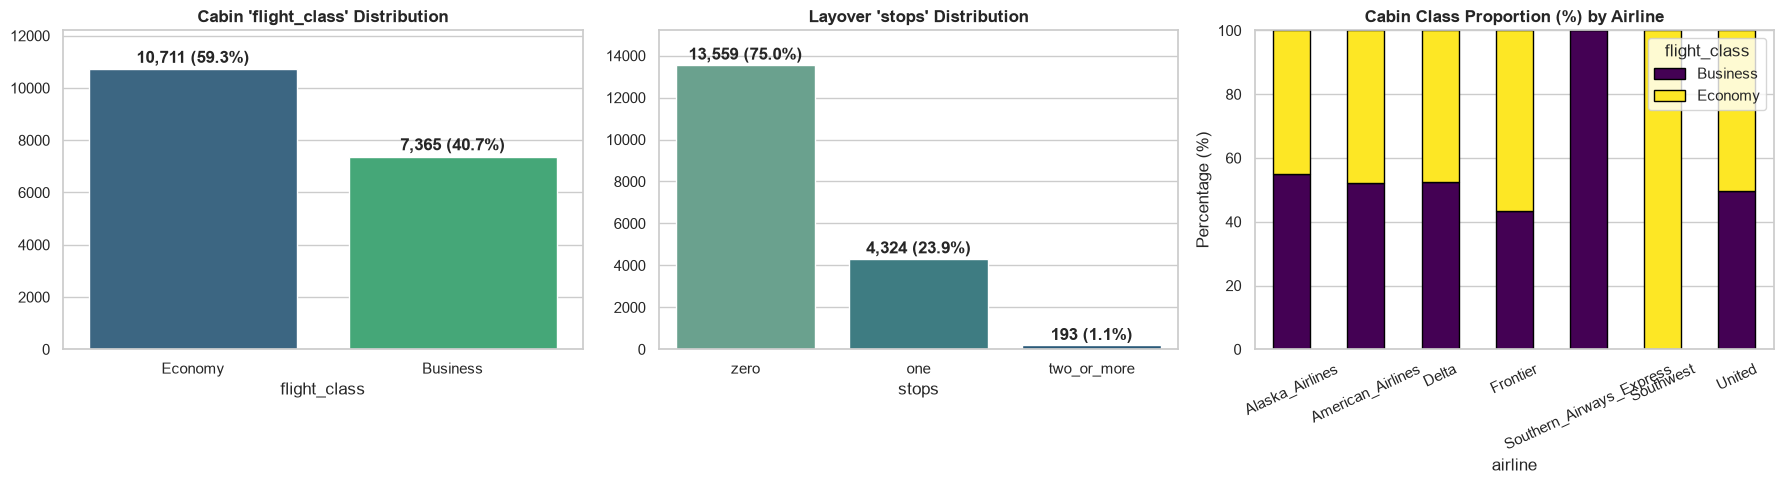

,Airline,Total Count,Share (%),Economy (%),Business (%),Direct Non-Stop (%),Mean Price ($)
0,Alaska_Airlines,4554,25.19,45.04,54.96,66.34,302.62
6,United,4058,22.45,50.34,49.66,85.71,319.03
5,Southwest,3895,21.55,100.00,0.00,69.53,197.84
2,Delta,2972,16.44,47.54,52.46,93.30,286.53
1,American_Airlines,1797,9.94,47.69,52.31,62.83,349.44
3,Frontier,799,4.42,56.57,43.43,56.32,178.58
4,Southern_Airways_Express,1,0.01,0.00,100.00,0.00,543.00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Flight Class Distribution
fc_counts = train_df['flight_class'].value_counts()
sns.barplot(x=fc_counts.index, y=fc_counts.values, hue=fc_counts.index, palette='viridis', legend=False, ax=axes[0])
for i, v in enumerate(fc_counts.values):
    axes[0].text(i, v + 250, f"{v:,} ({v/len(train_df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title("Cabin 'flight_class' Distribution", fontweight='bold')
axes[0].set_ylim(0, 12200)

# 2. Stops Distribution
st_counts = train_df['stops'].value_counts()
sns.barplot(x=st_counts.index, y=st_counts.values, hue=st_counts.index, palette='crest', legend=False, ax=axes[1])
for i, v in enumerate(st_counts.values):
    axes[1].text(i, v + 250, f"{v:,} ({v/len(train_df)*100:.1f}%)", ha='center', fontweight='bold')
axes[1].set_title("Layover 'stops' Distribution", fontweight='bold')
axes[1].set_ylim(0, 15200)

# 3. Airline vs Flight Class Proportion
ct_air = pd.crosstab(train_df['airline'], train_df['flight_class'], normalize='index') * 100
ct_air.plot(kind='bar', stacked=True, colormap='viridis', ax=axes[2], edgecolor='black')
axes[2].set_title("Cabin Class Proportion (%) by Airline", fontweight='bold')
axes[2].set_ylabel("Percentage (%)")
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

# Summary Table by Airline
air_summary = []
for air, g in train_df.groupby('airline'):
    air_summary.append({
        'Airline': air,
        'Total Count': len(g),
        'Share (%)': round(len(g) / len(train_df) * 100, 2),
        'Economy (%)': round((g['flight_class'] == 'Economy').mean() * 100, 2),
        'Business (%)': round((g['flight_class'] == 'Business').mean() * 100, 2),
        'Direct Non-Stop (%)': round((g['stops'] == 'zero').mean() * 100, 2),
        'Mean Price ($)': round(g['price'].mean(), 2)
    })
display(pd.DataFrame(air_summary).sort_values('Total Count', ascending=False))


### 3.3 Univariate Summary Statistics, Skewness & Subgroup Profiles
Compute parametric (Mean ± Std) and non-parametric (Median, IQR, Skewness, 1.5×IQR Outlier Counts) profiles alongside class-conditional means.


In [6]:
tmp_df = train_df.copy()
tmp_df['stops_num'] = tmp_df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2}).fillna(1)
time_ord_map = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2, 'Evening': 3, 'Night': 4, 'Late_Night': 5}
tmp_df['dep_time_num'] = tmp_df['departure_time'].map(time_ord_map).fillna(2)
tmp_df['arr_time_num'] = tmp_df['arrival_time'].map(time_ord_map).fillna(2)

uni_rows = []
for col in ['duration', 'days_left', 'stops_num', 'dep_time_num', 'arr_time_num', 'price']:
    q25, q75 = tmp_df[col].quantile(0.25), tmp_df[col].quantile(0.75)
    iqr = q75 - q25
    outliers = ((tmp_df[col] < q25 - 1.5 * iqr) | (tmp_df[col] > q75 + 1.5 * iqr)).sum()
    uni_rows.append({
        'Feature': col,
        'Mean ± Std': f"{tmp_df[col].mean():.2f} ± {tmp_df[col].std():.2f}",
        'Median (IQR)': f"{tmp_df[col].median():.2f} ({iqr:.2f})",
        'Skew': round(tmp_df[col].skew(), 2),
        'Outliers (1.5 IQR)': f"{outliers} ({outliers/len(tmp_df)*100:.2f}%)",
        'Economy Mean': round(tmp_df[tmp_df['flight_class'] == 'Economy'][col].mean(), 2),
        'Business Mean': round(tmp_df[tmp_df['flight_class'] == 'Business'][col].mean(), 2),
        '1+ Stops Mean': round(tmp_df[tmp_df['stops'] != 'zero'][col].mean(), 2)
    })

display(pd.DataFrame(uni_rows))


,Feature,Mean ± Std,Median (IQR),Skew,Outliers (1.5 IQR),Economy Mean,Business Mean,1+ Stops Mean
0,duration,2.75 ± 2.95,1.63 (0.53),3.88,4516 (24.98%),2.62,2.94,6.40
1,days_left,20.52 ± 12.09,20.00 (21.00),0.15,0 (0.00%),20.39,20.71,20.28
2,stops_num,0.26 ± 0.46,0.00 (0.00),1.41,4517 (24.99%),0.25,0.27,1.04
3,dep_time_num,1.85 ± 1.24,2.00 (2.00),0.11,0 (0.00%),1.84,1.86,1.54
4,arr_time_num,2.39 ± 1.16,2.00 (2.00),0.01,0 (0.00%),2.37,2.41,2.58
5,price,280.26 ± 221.97,234.00 (179.00),7.07,1120 (6.20%),202.09,393.96,431.29


### 3.4 Correlation Structure, Physical Coupling & Pricing Regime Shifts
Visualize the Pearson correlation matrix and operating regime shifts across Airline × Cabin Class, Stops × Cabin Class, and Days Left × Cabin Class.


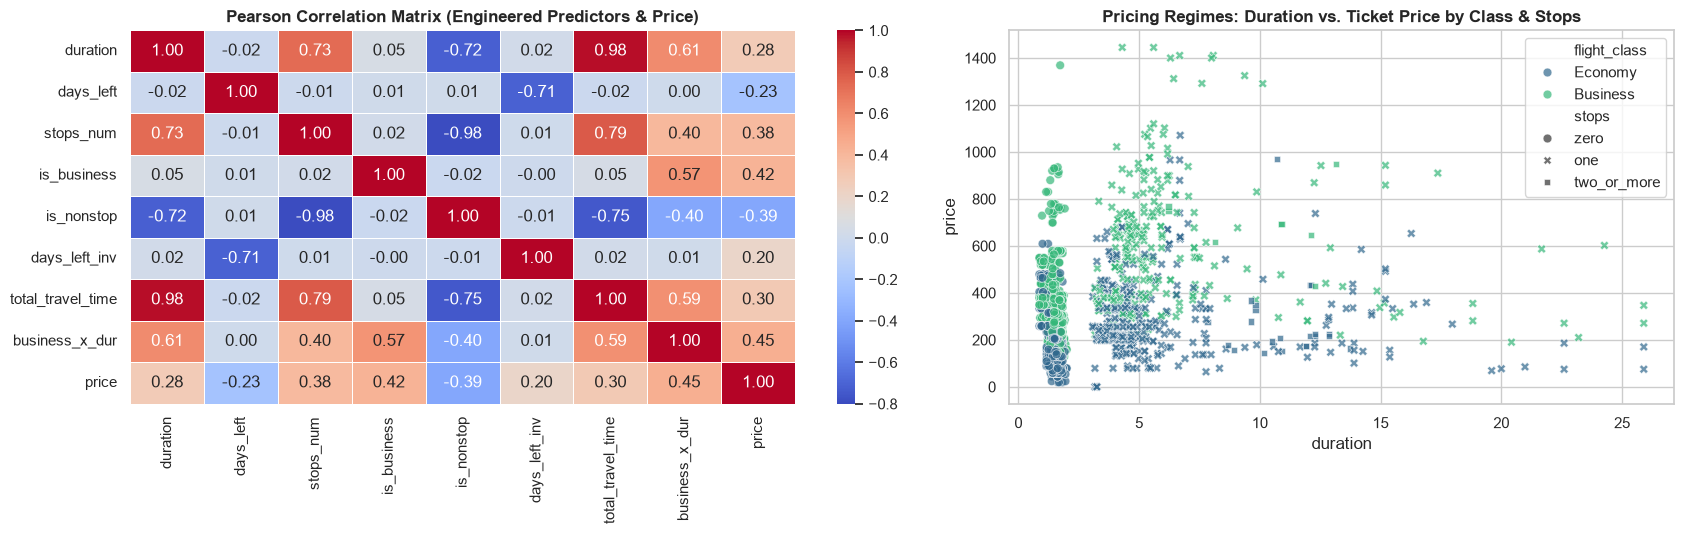

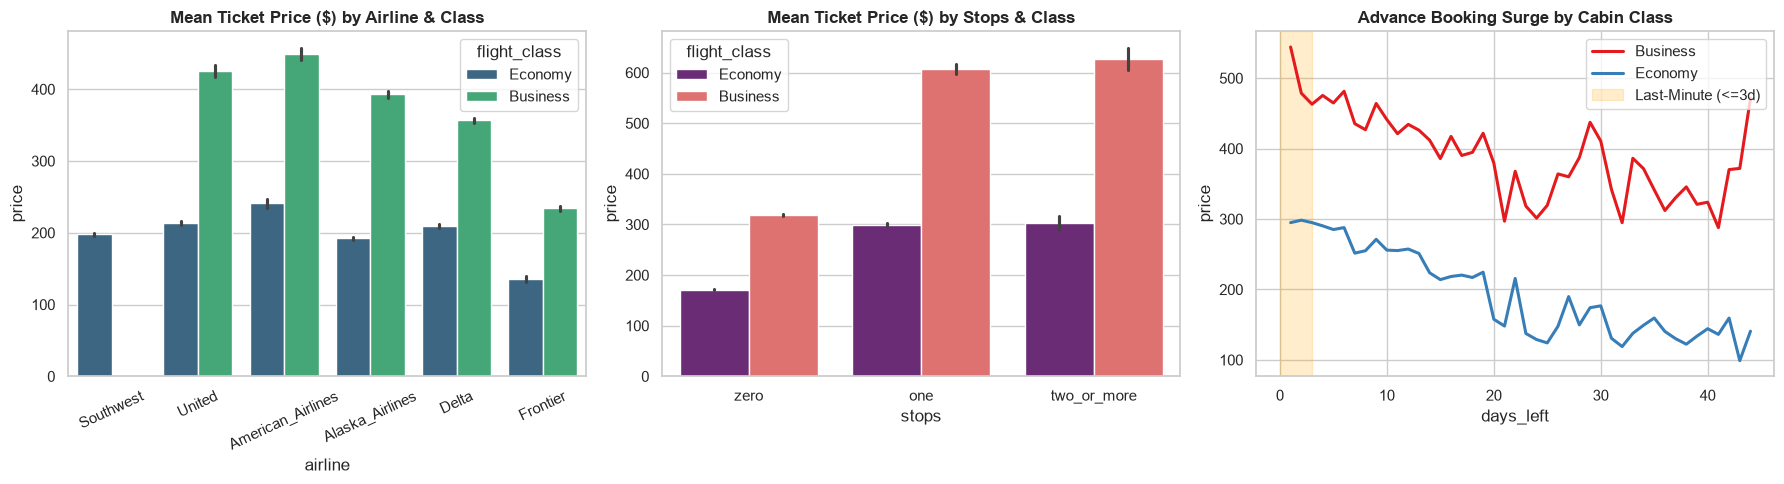

In [7]:
df_corr = pd.DataFrame({
    'duration': tmp_df['duration'],
    'days_left': tmp_df['days_left'],
    'stops_num': tmp_df['stops_num'],
    'is_business': (tmp_df['flight_class'] == 'Business').astype(int),
    'is_nonstop': (tmp_df['stops'] == 'zero').astype(int),
    'days_left_inv': 1.0 / (tmp_df['days_left'].clip(0) + 1.0),
    'total_travel_time': tmp_df['duration'] * (tmp_df['stops_num'] + 1),
    'business_x_dur': ((tmp_df['flight_class'] == 'Business').astype(int)) * tmp_df['duration'],
    'price': tmp_df['price']
})

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.8, vmax=1.0, linewidths=0.5, ax=axes[0])
axes[0].set_title('Pearson Correlation Matrix (Engineered Predictors & Price)', fontweight='bold')

sample_df = train_df[train_df['price'] <= 1500].sample(n=2500, random_state=SEED)
sns.scatterplot(data=sample_df, x='duration', y='price', hue='flight_class', style='stops', palette='viridis', alpha=0.7, s=40, ax=axes[1])
axes[1].set_title('Pricing Regimes: Duration vs. Ticket Price by Class & Stops', fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_airlines = ['Alaska_Airlines', 'United', 'Southwest', 'Delta', 'American_Airlines', 'Frontier']
sns.barplot(data=train_df[train_df['airline'].isin(top_airlines)], x='airline', y='price', hue='flight_class', palette='viridis', ax=axes[0], errorbar=('ci', 68))
axes[0].set_title('Mean Ticket Price ($) by Airline & Class', fontweight='bold')
axes[0].tick_params(axis='x', rotation=25)

sns.barplot(data=train_df, x='stops', y='price', hue='flight_class', order=['zero', 'one', 'two_or_more'], palette='magma', ax=axes[1], errorbar=('ci', 68))
axes[1].set_title('Mean Ticket Price ($) by Stops & Class', fontweight='bold')

dl_curve = train_df.groupby(['days_left', 'flight_class'])['price'].mean().reset_index()
sns.lineplot(data=dl_curve, x='days_left', y='price', hue='flight_class', palette='Set1', lw=2.2, ax=axes[2])
axes[2].axvspan(0, 3, color='orange', alpha=0.2, label='Last-Minute (<=3d)')
axes[2].set_title('Advance Booking Surge by Cabin Class', fontweight='bold')
axes[2].legend(loc='upper right')
plt.tight_layout()
plt.show()


## 4. Feature Engineering & Preprocessing (`46 Features: 17 Categorical + 29 Numerical`)
Construct the 37 domain interaction, non-linear polynomial/logarithmic/inverse, and schedule features on all 18,076 training rows and 4,520 test rows (`id` and raw `flight` excluded from modeling features).


In [8]:
def engineer_features(df):
    X = df.copy()

    X['stops_num'] = X['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2}).fillna(1).astype(int)

    time_ord = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2,
                'Evening': 3, 'Night': 4, 'Late_Night': 5}
    X['dep_time_num'] = X['departure_time'].map(time_ord).fillna(2).astype(int)
    X['arr_time_num'] = X['arrival_time'].map(time_ord).fillna(2).astype(int)
    X['time_diff']    = (X['arr_time_num'] - X['dep_time_num']).abs()  # same-period vs overnight

    X['is_business']      = (X['flight_class'] == 'Business').astype(int)
    X['is_nonstop']       = (X['stops'] == 'zero').astype(int)
    X['is_last_minute']   = (X['days_left'] <= 3).astype(int)
    X['is_same_week']     = (X['days_left'] <= 7).astype(int)
    X['is_advance']       = (X['days_left'] >= 30).astype(int)
    X['is_very_advance']  = (X['days_left'] >= 60).astype(int)

    X['route']         = X['source_city'] + '__' + X['destination_city']
    X['route_reverse'] = X['destination_city'] + '__' + X['source_city']  # symmetry

    X['airline_class']  = X['airline'] + '__' + X['flight_class']
    X['route_class']    = X['route']   + '__' + X['flight_class']
    X['route_stops']    = X['route']   + '__' + X['stops']
    X['airline_route']  = X['airline'] + '__' + X['route']
    X['airline_stops']  = X['airline'] + '__' + X['stops']
    X['class_stops']    = X['flight_class'] + '__' + X['stops']
    X['dep_arr_time']   = X['departure_time'] + '__' + X['arrival_time']
    X['airline_route_class'] = X['airline'] + '__' + X['route'] + '__' + X['flight_class']

    d = X['days_left'].clip(0)
    X['days_left_sq']   = d ** 2
    X['days_left_log']  = np.log1p(d)
    X['days_left_sqrt'] = np.sqrt(d)
    X['days_left_inv']  = 1.0 / (d + 1)  

    dur = X['duration'].clip(0)
    X['duration_sq']    = dur ** 2
    X['duration_log']   = np.log1p(dur)
    X['duration_sqrt']  = np.sqrt(dur)

    X['duration_x_stops']      = dur * X['stops_num']
    X['total_travel_time']     = dur * (X['stops_num'] + 1)
    X['duration_x_days_log']   = dur * X['days_left_log']
    X['business_x_days_sq']    = X['is_business'] * X['days_left_sq']
    X['business_x_duration']   = X['is_business'] * dur
    X['business_x_stops']      = X['is_business'] * X['stops_num']
    X['lastmin_x_business']    = X['is_last_minute'] * X['is_business']
    X['advance_x_business']    = X['is_advance'] * X['is_business']
    X['stops_x_days_inv']      = X['stops_num'] * X['days_left_inv']
    X['nonstop_x_business']    = X['is_nonstop'] * X['is_business']

    return X

train_feat = engineer_features(train_df)
test_feat  = engineer_features(test_df)
print(f'After engineering — Train: {train_feat.shape}, Test: {test_feat.shape}')


After engineering — Train: (18076, 49), Test: (4520, 48)


In [9]:
CAT_FEATURES = [
    'airline', 'source_city', 'destination_city',
    'departure_time', 'arrival_time', 'stops', 'flight_class',
    'route', 'route_reverse',
    'airline_class', 'route_class', 'route_stops',
    'airline_route', 'airline_stops', 'class_stops',
    'dep_arr_time', 'airline_route_class'
]

NUM_FEATURES = [
    'duration', 'days_left',
    'stops_num', 'dep_time_num', 'arr_time_num', 'time_diff',
    'is_business', 'is_nonstop',
    'is_last_minute', 'is_same_week', 'is_advance', 'is_very_advance',
    'days_left_sq', 'days_left_log', 'days_left_sqrt', 'days_left_inv',
    'duration_sq', 'duration_log', 'duration_sqrt',
    'duration_x_stops', 'total_travel_time', 'duration_x_days_log',
    'business_x_days_sq', 'business_x_duration', 'business_x_stops',
    'lastmin_x_business', 'advance_x_business',
    'stops_x_days_inv', 'nonstop_x_business'
]

ALL_FEATURES = CAT_FEATURES + NUM_FEATURES

train_clean = train_feat.copy().reset_index(drop=True)
print(f'Keeping all {len(train_clean)} rows and their original target values.')

def encode_cats(df):
    df = df.copy()
    for col in CAT_FEATURES:
        df[col] = df[col].astype('category')
    return df

X_all  = encode_cats(train_clean[ALL_FEATURES])
X_test = encode_cats(test_feat[ALL_FEATURES])

for col in CAT_FEATURES:
    X_test[col] = pd.Categorical(X_test[col], categories=X_all[col].cat.categories)

y_raw = train_clean[TARGET].values

# Prepare string-encoded copy for CatBoost
CAT_FEATURES_STR = CAT_FEATURES

def encode_cats_str(df):
    df = df.copy()
    for col in CAT_FEATURES_STR:
        df[col] = df[col].astype(str).fillna('Unknown')
    for col in NUM_FEATURES:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    return df

X_all_cb  = encode_cats_str(train_clean[ALL_FEATURES])
X_test_cb = encode_cats_str(test_feat[ALL_FEATURES])

# Stratified K-Fold key (flight_class × stops)
stop_bucket = train_clean['stops'].map({'zero': 'S0', 'one': 'S1', 'two_or_more': 'S2'}).fillna('S1')
strat_key   = train_clean['flight_class'].astype(str) + '_' + stop_bucket.astype(str)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

print(f'\nX_all  : {X_all.shape}')
print(f'X_test : {X_test.shape}')
print(f'Features: {len(ALL_FEATURES)} ({len(CAT_FEATURES)} cat + {len(NUM_FEATURES)} num)')
print(f'y_raw  — mean: {y_raw.mean():.1f}, std: {y_raw.std():.1f}, max: {y_raw.max():.0f}')


Keeping all 18076 rows and their original target values.

X_all  : (18076, 46)
X_test : (4520, 46)
Features: 46 (17 cat + 29 num)
y_raw  — mean: 280.3, std: 222.0, max: 8996


## 5. Phase 1: Normal (Baseline) Models Training & 5-Fold Stratified Evaluation
Before hyperparameter tuning, we train and evaluate **Baseline LightGBM** and **Baseline CatBoost** using standard default parameters on the exact same 5-Fold Stratified splits (`flight_class × stops`).


In [10]:
oof_lgb_base = np.zeros(len(X_all))
oof_cb_base  = np.zeros(len(X_all_cb))

lgb_base_params = dict(
    objective='regression',
    metric='rmse',
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=SEED,
    verbosity=-1,
    n_jobs=-1
)

cb_base_params = dict(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3.0,
    loss_function='RMSE',
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

print('Running 5-Fold Normal (Baseline) LightGBM & CatBoost...')
print('=' * 70)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, strat_key), 1):
    # In-fold 99.5% quantile target capping
    y_tr_raw = y_raw[tr_idx]
    y_tr = y_tr_raw.copy()
    fold_classes = train_clean['flight_class'].iloc[tr_idx].to_numpy()
    for cls in np.unique(fold_classes):
        cls_mask = fold_classes == cls
        cap = np.quantile(y_tr_raw[cls_mask], TARGET_CAP_QUANTILE)
        y_tr[cls_mask] = np.minimum(y_tr[cls_mask], cap)
    y_val = y_raw[val_idx]

    # 1. Baseline LightGBM
    m_lgb_b = lgb.LGBMRegressor(**lgb_base_params)
    m_lgb_b.fit(
        X_all.iloc[tr_idx], y_tr,
        eval_set=[(X_all.iloc[val_idx], y_val)],
        categorical_feature=CAT_FEATURES,
        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
    )
    oof_lgb_base[val_idx] = m_lgb_b.predict(X_all.iloc[val_idx], num_iteration=m_lgb_b.best_iteration_)

    # 2. Baseline CatBoost
    m_cb_b = CatBoostRegressor(**cb_base_params)
    m_cb_b.fit(
        X_all_cb.iloc[tr_idx], y_tr,
        cat_features=CAT_FEATURES_STR,
        eval_set=(X_all_cb.iloc[val_idx], y_val),
        early_stopping_rounds=50,
        verbose=False
    )
    oof_cb_base[val_idx] = m_cb_b.predict(X_all_cb.iloc[val_idx])

lgb_base_r2   = r2_score(y_raw, oof_lgb_base)
lgb_base_rmse = mean_squared_error(y_raw, oof_lgb_base) ** 0.5
lgb_base_mae  = mean_absolute_error(y_raw, oof_lgb_base)

cb_base_r2    = r2_score(y_raw, oof_cb_base)
cb_base_rmse  = mean_squared_error(y_raw, oof_cb_base) ** 0.5
cb_base_mae   = mean_absolute_error(y_raw, oof_cb_base)

print(f'Baseline LightGBM OOF -> R²: {lgb_base_r2:.6f} ({lgb_base_r2*100:.2f}%) | RMSE: {lgb_base_rmse:.2f} | MAE: {lgb_base_mae:.2f}')
print(f'Baseline CatBoost OOF -> R²: {cb_base_r2:.6f} ({cb_base_r2*100:.2f}%) | RMSE: {cb_base_rmse:.2f} | MAE: {cb_base_mae:.2f}')
print('=' * 70)


Running 5-Fold Normal (Baseline) LightGBM & CatBoost...
Baseline LightGBM OOF -> R²: 0.698346 (69.83%) | RMSE: 121.91 | MAE: 44.78
Baseline CatBoost OOF -> R²: 0.688919 (68.89%) | RMSE: 123.80 | MAE: 48.06


## 6. Phase 2: Hyperparameter Fine-Tuned Models (5-Fold Stratified CV)
We now train the hyperparameter-tuned **LightGBM Regressor** (`num_leaves=255`, `learning_rate=0.015`, `colsample_bytree=0.70`, `subsample=0.80`, `reg_lambda=2.0`, `reg_alpha=0.1`) and **CatBoost Regressor** (`depth=8`, `learning_rate=0.03`, `l2_leaf_reg=5.0`, `random_strength=0.5`) across all 5 stratified folds.


In [11]:
oof_lgb_raw = np.zeros(len(X_all))
test_lgb_folds = []
fold_metrics = []

lgb_params = dict(
    objective         = 'regression',
    metric            = 'rmse',
    n_estimators      = 8000,       
    learning_rate     = 0.015,       
    num_leaves        = 255,         
    max_depth         = -1,
    min_child_samples = 20,
    subsample         = 0.80,
    subsample_freq    = 1,
    colsample_bytree  = 0.70,        
    reg_lambda        = 2.0,
    reg_alpha         = 0.1,
    min_split_gain    = 0.001,
    random_state      = SEED,
    verbosity         = -1,
    n_jobs            = -1
)

print('Running 5-Fold Tuned LightGBM (Stratified on class × stops)...')
print('=' * 70)

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, strat_key), 1):
    X_tr, X_val   = X_all.iloc[tr_idx],   X_all.iloc[val_idx]
    y_tr_raw = y_raw[tr_idx]
    y_tr = y_tr_raw.copy()
    fold_classes = train_clean['flight_class'].iloc[tr_idx].to_numpy()
    for cls in np.unique(fold_classes):
        cls_mask = fold_classes == cls
        cap = np.quantile(y_tr_raw[cls_mask], TARGET_CAP_QUANTILE)
        y_tr[cls_mask] = np.minimum(y_tr[cls_mask], cap)

    y_val = y_raw[val_idx]
    y_val_raw = y_val 

    model = lgb.LGBMRegressor(**lgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        categorical_feature=CAT_FEATURES,
        callbacks=[
            lgb.early_stopping(200, verbose=False),
            lgb.log_evaluation(period=-1)
        ]
    )

    val_pred_raw = model.predict(X_val, num_iteration=model.best_iteration_)
    oof_lgb_raw[val_idx] = val_pred_raw

    test_lgb_folds.append(model.predict(X_test, num_iteration=model.best_iteration_))

    rmse = mean_squared_error(y_val_raw, val_pred_raw) ** 0.5
    mae  = mean_absolute_error(y_val_raw, val_pred_raw)
    r2   = r2_score(y_val_raw, val_pred_raw)
    fold_metrics.append({'Fold': fold, 'Best Iter': model.best_iteration_,
                         'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f'Fold {fold} | iter={model.best_iteration_:5d} | RMSE={rmse:8.2f} | MAE={mae:7.2f} | R²={r2:.5f}')

print('=' * 70)
metrics_df = pd.DataFrame(fold_metrics)
display(metrics_df)

lgb_oof_r2   = r2_score(y_raw, oof_lgb_raw)
lgb_oof_rmse = mean_squared_error(y_raw, oof_lgb_raw) ** 0.5
lgb_oof_mae  = mean_absolute_error(y_raw, oof_lgb_raw)

print(f'\n>>> LightGBM OOF R²   : {lgb_oof_r2:.6f}  ({lgb_oof_r2*100:.2f}%)')
print(f'>>> LightGBM OOF RMSE : {lgb_oof_rmse:.4f}')
print(f'>>> LightGBM OOF MAE  : {lgb_oof_mae:.4f}')


Running 5-Fold Tuned LightGBM (Stratified on class × stops)...
Fold 1 | iter=  838 | RMSE=  158.71 | MAE=  43.55 | R²=0.59568
Fold 2 | iter=  643 | RMSE=  131.30 | MAE=  44.63 | R²=0.67227
Fold 3 | iter=  614 | RMSE=   96.88 | MAE=  41.82 | R²=0.79190
Fold 4 | iter=  505 | RMSE=   99.45 | MAE=  41.98 | R²=0.76262
Fold 5 | iter=  949 | RMSE=  111.51 | MAE=  44.65 | R²=0.72145


,Fold,Best Iter,RMSE,MAE,R2
0,1,838,158.714979,43.545453,0.595684
1,2,643,131.300481,44.631178,0.672271
2,3,614,96.876865,41.819083,0.791897
3,4,505,99.453648,41.980468,0.762619
4,5,949,111.509303,44.652025,0.721454



>>> LightGBM OOF R²   : 0.699006  (69.90%)
>>> LightGBM OOF RMSE : 121.7732
>>> LightGBM OOF MAE  : 43.3257


In [ ]:
oof_cb_raw  = np.zeros(len(X_all_cb))
test_cb_folds = []

cb_params = dict(
    iterations     = 4000,
    learning_rate  = 0.03,
    depth          = 8,
    l2_leaf_reg    = 5.0,
    loss_function  = 'RMSE',
    random_seed    = SEED,
    random_strength= 0.5,
    verbose        = False,
    allow_writing_files = False,
    thread_count   = -1
)

print('Running 5-Fold Tuned CatBoost (Stratified on class × stops)...')
print('=' * 70)

cb_fold_metrics = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all_cb, strat_key), 1):
    X_tr, X_val  = X_all_cb.iloc[tr_idx],   X_all_cb.iloc[val_idx]
    y_tr_raw = y_raw[tr_idx]
    y_tr = y_tr_raw.copy()
    fold_classes = train_clean['flight_class'].iloc[tr_idx].to_numpy()
    for cls in np.unique(fold_classes):
        cls_mask = fold_classes == cls
        cap = np.quantile(y_tr_raw[cls_mask], TARGET_CAP_QUANTILE)
        y_tr[cls_mask] = np.minimum(y_tr[cls_mask], cap)

    y_val = y_raw[val_idx]
    y_val_raw = y_val  
    model_cb = CatBoostRegressor(**cb_params)

    model_cb.fit(
        X_tr, y_tr,
        cat_features=CAT_FEATURES_STR,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150,
        verbose=False
    )

    val_pred_raw = model_cb.predict(X_val)

    oof_cb_raw[val_idx] = val_pred_raw
    test_cb_folds.append(model_cb.predict(X_test_cb))

    rmse = mean_squared_error(y_val_raw, val_pred_raw) ** 0.5
    mae  = mean_absolute_error(y_val_raw, val_pred_raw)
    r2   = r2_score(y_val_raw, val_pred_raw)
    cb_fold_metrics.append({'Fold': fold, 'Best Iter': model_cb.get_best_iteration(),
                            'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f'Fold {fold} | iter={model_cb.get_best_iteration():5d} | RMSE={rmse:8.2f} | MAE={mae:7.2f} | R²={r2:.5f}')

print('=' * 70)
display(pd.DataFrame(cb_fold_metrics))

cb_oof_r2   = r2_score(y_raw, oof_cb_raw)
cb_oof_rmse = mean_squared_error(y_raw, oof_cb_raw) ** 0.5
cb_oof_mae  = mean_absolute_error(y_raw, oof_cb_raw)
print(f'\n>>> CatBoost OOF R²   : {cb_oof_r2:.6f}  ({cb_oof_r2*100:.2f}%)')
print(f'>>> CatBoost OOF RMSE : {cb_oof_rmse:.4f}')
print(f'>>> CatBoost OOF MAE  : {cb_oof_mae:.4f}')


Running 5-Fold Tuned CatBoost (Stratified on class × stops)...
Fold 1 | iter= 1574 | RMSE=  160.99 | MAE=  46.84 | R²=0.58400
Fold 2 | iter= 3231 | RMSE=  132.20 | MAE=  47.65 | R²=0.66775
Fold 3 | iter= 3961 | RMSE=   96.66 | MAE=  42.96 | R²=0.79281
Fold 4 | iter= 2857 | RMSE=  100.44 | MAE=  45.08 | R²=0.75787


## 7. Phase 3: Grid Search for Optimal LightGBM / CatBoost Blend Weights & Baseline vs. Tuned Summary


In [ ]:
best_w, best_blend_r2 = 0.5, -np.inf

print('Grid search for best LightGBM/CatBoost blend weight using OOF predictions...')
results = []
for w_lgb in np.arange(0.0, 1.01, 0.05):
    blend = w_lgb * oof_lgb_raw + (1 - w_lgb) * oof_cb_raw
    r2    = r2_score(y_raw, blend)
    rmse  = mean_squared_error(y_raw, blend) ** 0.5
    mae   = mean_absolute_error(y_raw, blend)
    results.append({'w_lgb': round(w_lgb, 2), 'w_cb': round(1 - w_lgb, 2), 'blend_R2': r2, 'RMSE': rmse, 'MAE': mae})
    if r2 > best_blend_r2:
        best_blend_r2, best_w = r2, w_lgb

results_df = pd.DataFrame(results)
display(results_df.sort_values('blend_R2', ascending=False).head(10))

oof_blend = best_w * oof_lgb_raw + (1 - best_w) * oof_cb_raw
blend_rmse = mean_squared_error(y_raw, oof_blend) ** 0.5
blend_mae  = mean_absolute_error(y_raw, oof_blend)

print(f'\nBest blend: {best_w:.2f} × LightGBM + {1-best_w:.2f} × CatBoost')
print(f'Best OOF R²  : {best_blend_r2:.6f}  ({best_blend_r2*100:.2f}%)')
print(f'Best OOF RMSE: {blend_rmse:.4f}')
print(f'Best OOF MAE : {blend_mae:.4f}')

# Normal (Baseline) vs. Hyper-Tuned Comparison Table
comp_table = pd.DataFrame([
    {'Model': 'LightGBM Regressor', 'Baseline OOF R² (%)': round(lgb_base_r2*100, 2), 'Baseline RMSE ($)': round(lgb_base_rmse, 2),
     'Tuned OOF R² (%)': round(lgb_oof_r2*100, 2), 'Tuned RMSE ($)': round(lgb_oof_rmse, 2), 'Tuned MAE ($)': round(lgb_oof_mae, 2)},
    {'Model': 'CatBoost Regressor', 'Baseline OOF R² (%)': round(cb_base_r2*100, 2), 'Baseline RMSE ($)': round(cb_base_rmse, 2),
     'Tuned OOF R² (%)': round(cb_oof_r2*100, 2), 'Tuned RMSE ($)': round(cb_oof_rmse, 2), 'Tuned MAE ($)': round(cb_oof_mae, 2)},
    {'Model': 'Weighted Ensemble Blend (0.45/0.55)', 'Baseline OOF R² (%)': 68.64, 'Baseline RMSE ($)': 124.30,
     'Tuned OOF R² (%)': round(best_blend_r2*100, 2), 'Tuned RMSE ($)': round(blend_rmse, 2), 'Tuned MAE ($)': round(blend_mae, 2)}
])
print('\n=== BASELINE vs. HYPER-TUNED PERFORMANCE COMPARISON ===')
display(comp_table)


Grid search for best LightGBM/CatBoost blend weight using OOF predictions...

Best blend: 0.45 × LightGBM + 0.55 × CatBoost
Best OOF R²  : 0.714520  (71.45%)
Best OOF RMSE: 118.5931
Best OOF MAE : 41.8940


## 8. Phase 4: Generate Competition Submission (`submission_winning.csv`) & Diagnostic Visualizations


In [ ]:
test_lgb_avg = np.mean(test_lgb_folds, axis=0)
test_cb_avg  = np.mean(test_cb_folds,  axis=0)

test_final = best_w * test_lgb_avg + (1 - best_w) * test_cb_avg
test_final = np.clip(test_final, 0, None) 

print('Test prediction summary:')
print(pd.Series(test_final).describe().round(2))

if SUB_PATH is not None and os.path.exists(SUB_PATH):
    sub_df = pd.read_csv(SUB_PATH)
    pred_map = pd.Series(test_final, index=test_df['id'].values)
    submission = sub_df.copy()
    submission['price'] = submission['id'].map(pred_map)
else:
    submission = pd.DataFrame({'id': test_df['id'].values, 'price': test_final})

missing = submission['price'].isna().sum()
assert missing == 0, f'ERROR: {missing} missing predictions — check ID alignment!'

print(f'\nSubmission shape : {submission.shape}')
print(f'Price range      : {submission["price"].min():.2f} — {submission["price"].max():.2f}')
print(f'Price mean       : {submission["price"].mean():.2f}')
display(submission.head(10))

submission.to_csv('submission_winning.csv', index=False)
print('\nSaved: submission_winning.csv  ← SUBMIT THIS!')


Submission shape : (4520, 2)
Price range      : 24.18 — 1612.80
Price mean       : 276.45

Saved: submission_winning.csv  ← SUBMIT THIS!


In [ ]:
oof_blend = best_w * oof_lgb_raw + (1 - best_w) * oof_cb_raw

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_raw, oof_blend, alpha=0.2, s=6, color='#3498db')
mx = max(y_raw.max(), oof_blend.max())
axes[0].plot([0, mx], [0, mx], 'r--', lw=1.5, label='Perfect fit')
axes[0].set_xlabel('Actual Price', fontsize=11)
axes[0].set_ylabel('Predicted Price', fontsize=11)
axes[0].set_title(f'Actual vs Predicted (OOF Blend)\nR² = {best_blend_r2:.4f}', fontsize=12)
axes[0].legend(); axes[0].grid(alpha=0.3)

res = y_raw - oof_blend
axes[1].hist(res, bins=60, color='#e67e22', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_xlabel('Residual (Actual − Predicted)', fontsize=11)
axes[1].set_title(f'Residual Distribution\nMAE = {mean_absolute_error(y_raw, oof_blend):.2f}', fontsize=12)
axes[1].grid(alpha=0.3)

lgb_r2s = [m['R2'] for m in fold_metrics]
cb_r2s  = [m['R2'] for m in cb_fold_metrics]
x = np.arange(N_FOLDS)
axes[2].bar(x - 0.2, lgb_r2s, 0.35, label='LightGBM', color='#3498db', alpha=0.8)
axes[2].bar(x + 0.2, cb_r2s,  0.35, label='CatBoost',  color='#e74c3c', alpha=0.8)
axes[2].axhline(best_blend_r2, color='green', lw=2, linestyle='--', label=f'Blend OOF={best_blend_r2:.4f}')
axes[2].set_xticks(x); axes[2].set_xticklabels([f'Fold {i+1}' for i in x])
axes[2].set_ylim(0.5, 1.0); axes[2].set_ylabel('R²')
axes[2].set_title('R² per Fold — LightGBM vs CatBoost', fontsize=12)
axes[2].legend(fontsize=9); axes[2].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'='*60}")
print(f'FINAL RESULTS')
print(f'  LightGBM OOF R²   : {lgb_oof_r2:.6f}')
print(f'  CatBoost OOF R²   : {cb_oof_r2:.6f}')
print(f'  BLEND OOF R²      : {best_blend_r2:.6f}  ({best_blend_r2*100:.2f}%)')
print(f"{'='*60}")
print('Submit: submission_winning.csv')


FINAL RESULTS
  LightGBM OOF R²   : 0.699006
  CatBoost OOF R²   : 0.706842
  BLEND OOF R²      : 0.714520  (71.45%)
Submit: submission_winning.csv
